# Pipeline reproducible para el dataset Iris
**Seminario de Investigación — Ciencia de Datos**
**Autor:** Aisha Valentina Brown Moreno

Este notebook recorre, paso a paso y con código comentado, el pipeline del repositorio:

| Requisito | Dónde está en el repositorio | Sección del notebook |
|---|---|---|
| 3.2 Automatización con un solo comando | `Makefile`, `run_pipeline.py` | 7 |
| 3.3 Validación de datos sin librerías externas | `src/validate.py` | 3 |
| 3.4 Contrato de Datos en JSON | `contracts/data_contract.json` | 2 y 6 |
| 3.5 README técnico | `README.md` | — |
| Pruebas automatizadas | `tests/` | 8 |
| Evidencia de ejecución | `reports/pipeline_run.log` | 7 |

> El notebook **no duplica la lógica**: importa los mismos módulos de `src/` que usa el pipeline,
> de modo que lo que se ve aquí es exactamente lo que se ejecuta con `make all`.

## 0. Preparación del entorno

In [1]:
# Librerías estándar
import json, os, subprocess, sys, tempfile
from pathlib import Path

# Ubicamos la raíz del proyecto (el notebook vive en notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)                    # trabajamos siempre desde la raíz
sys.path.insert(0, str(ROOT))     # para poder hacer "from src import ..."

# Librerías de terceros (solo para análisis y modelo, NO para validar)
import matplotlib.pyplot as plt
import pandas as pd

# Módulos propios del pipeline
from src import config
from src.data_loader import load_iris
from src.validate import load_contract, validate_training_file, validate_record

print("Raíz del proyecto:", ROOT.name)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)

Raíz del proyecto: iris-pipeline
Python: 3.13.18 | pandas: 3.0.5


## 1. Exploración rápida de los datos
El archivo `data/raw/iris.csv` viene en formato de *scikit-learn*: la primera fila son metadatos
(`150,4,setosa,versicolor,virginica`) y la última columna es la especie codificada (0, 1, 2).

In [2]:
# Vista cruda de las 3 primeras líneas del archivo
with open(config.RAW_DATA_PATH, encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline().rstrip())

150,4,setosa,versicolor,virginica
5.1,3.5,1.4,0.2,0
4.9,3.0,1.4,0.2,0


In [3]:
# Carga con nombres de columna legibles (definidos en src/config.py)
df = load_iris()
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
# Estadísticos descriptivos: sirven para fijar los rangos lógicos del contrato
df.describe().round(2)

,sepal_length,sepal_width,petal_length,petal_width,target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00


In [5]:
# Balance de clases: 50 flores por especie
etiquetas = {0: "setosa", 1: "versicolor", 2: "virginica"}
df["target"].map(etiquetas).value_counts()

target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

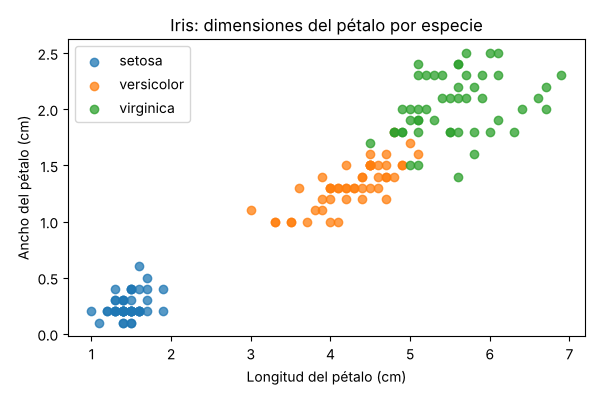

In [6]:
# Gráfica: las variables del pétalo separan casi perfectamente las especies
fig, ax = plt.subplots(figsize=(6, 4))
for clase, nombre in etiquetas.items():
    sub = df[df["target"] == clase]
    ax.scatter(sub["petal_length"], sub["petal_width"], label=nombre, alpha=0.75)
ax.set_xlabel("Longitud del pétalo (cm)")
ax.set_ylabel("Ancho del pétalo (cm)")
ax.set_title("Iris: dimensiones del pétalo por especie")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Contrato de Datos (requisito 3.4)
`contracts/data_contract.json` es la **fuente única de verdad**: define campos, tipos, rangos y
ejemplos de entrada válida e inválida. La validación lee sus reglas de ahí, así que si el contrato
cambia, la validación cambia sin tocar código.

In [7]:
contrato = load_contract()

# Resumen del esquema de entrada en forma de tabla
esquema = pd.DataFrame(contrato["input_schema"]["fields"]).T
esquema

,type,description,min,max
sepal_length,float,Longitud del sépalo en cm,4.0,8.5
sepal_width,float,Ancho del sépalo en cm,1.5,5.0
petal_length,float,Longitud del pétalo en cm,0.5,7.5
petal_width,float,Ancho del pétalo en cm,0.05,3.0


In [8]:
# Ejemplos oficiales incluidos en el contrato
print("Entrada VÁLIDA:")
print(json.dumps(contrato["examples"]["valid_input"], indent=2))
print("\nEntrada INVÁLIDA:")
print(json.dumps(contrato["examples"]["invalid_input"], indent=2, ensure_ascii=False))

Entrada VÁLIDA:
{
  "sepal_length": 5.1,
  "sepal_width": 3.5,
  "petal_length": 1.4,
  "petal_width": 0.2
}

Entrada INVÁLIDA:
{
  "sepal_length": "cinco",
  "sepal_width": null,
  "petal_length": 12.0,
  "petal_width": -0.3,
  "color": "morado"
}


## 3. Validación de datos de entrada (requisito 3.3)
`src/validate.py` usa **solo la biblioteca estándar** (`csv`, `json`, `math`). Verifica:
1. **Tipos**: cada variable debe ser numérica y la etiqueta un entero.
2. **Nulos**: vacíos, `NA`, `NaN`, `null`, `?` se rechazan.
3. **Rangos lógicos**: cada medida debe estar dentro del `[min, max]` del contrato.

Además revisa la estructura: número de columnas, encabezado coherente y clases permitidas.

In [9]:
# 3.1 Validación del dataset original
reporte = validate_training_file(config.RAW_DATA_PATH)
print(json.dumps(reporte, indent=2, ensure_ascii=False))

{
  "file": "data/raw/iris.csv",
  "status": "OK",
  "total_rows": 150,
  "valid_rows": 150,
  "n_errors": 0,
  "errors": [],
  "warnings": [],
  "class_counts": {
    "0": 50,
    "1": 50,
    "2": 50
  }
}


In [10]:
# 3.2 Prueba negativa: copiamos el CSV e inyectamos errores a propósito
lineas = config.RAW_DATA_PATH.read_text(encoding="utf-8").splitlines()
lineas[1] = "5.1,,1.4,0.2,0"          # nulo en sepal_width
lineas[2] = "4.9,tres,1.4,0.2,0"      # tipo incorrecto
lineas[3] = "4.7,3.2,25.0,0.2,0"      # petal_length fuera de rango
lineas[4] = "4.6,3.1,1.5,0.2,5"       # especie inexistente

with tempfile.TemporaryDirectory() as tmp:
    ruta_mala = Path(tmp) / "iris_corrupto.csv"
    ruta_mala.write_text("\n".join(lineas), encoding="utf-8")
    reporte_malo = validate_training_file(ruta_mala)

print("Estado:", reporte_malo["status"])
print("Filas válidas:", reporte_malo["valid_rows"], "de", reporte_malo["total_rows"])
for e in reporte_malo["errors"]:
    print("  -", e)

Estado: FAILED
Filas válidas: 146 de 150
  - línea 2: sepal_width: valor nulo
  - línea 3: sepal_width: tipo inválido (se esperaba float, llegó 'tres')
  - línea 4: petal_length: 25.0 fuera de rango [0.5, 7.5]
  - línea 5: target: 5 no está en [0, 1, 2]


In [11]:
# 3.3 Validación de registros individuales (lo que ocurrirá en inferencia)
for nombre in ["valid_input", "invalid_input"]:
    errores = validate_record(contrato["examples"][nombre], contrato)
    print(f"{nombre}: {'VÁLIDO' if not errores else 'INVÁLIDO'}")
    for e in errores:
        print("   -", e)

valid_input: VÁLIDO
invalid_input: INVÁLIDO
   - campo no permitido por el contrato: color
   - sepal_length: tipo inválido (se esperaba float, llegó str)
   - sepal_width: valor nulo no permitido
   - petal_length: 12.0 fuera de rango [0.5, 7.5]
   - petal_width: -0.3 fuera de rango [0.05, 3.0]


## 4. Entrenamiento
`src/train.py` vuelve a validar los datos (si fallan, no entrena), divide 80/20 de forma
**estratificada** con semilla fija (`random_state=42`) y entrena un `Pipeline` de
`StandardScaler + LogisticRegression`. Encadenar el escalado evita fuga de información.

In [12]:
from src import train

codigo = train.main()          # 0 = éxito
print("Código de salida:", codigo)

metricas_train = json.loads((config.REPORTS_DIR / "train_metrics.json").read_text())
metricas_train

[train] train: 120 filas | test: 30 filas
[train] accuracy CV (5 folds): 0.9583 ± 0.0264
[train] modelo guardado en iris_model.joblib
Código de salida: 0


{
 "cv_folds": 5,
 "cv_accuracy_mean": 0.9583,
 "cv_accuracy_std": 0.0264,
 "cv_scores": [
  0.9583,
  1.0,
  0.9583,
  0.9583,
  0.9167
 ],
 "train_accuracy": 0.9583,
 "n_train": 120,
 "n_test": 30,
 "random_state": 42
}

## 5. Validación del modelo
`src/evaluate.py` mide el desempeño sobre las 30 flores de prueba (nunca vistas) y aplica una
**compuerta de calidad**: si la exactitud es menor que 0.90, el pipeline falla.

In [13]:
from src import evaluate

codigo = evaluate.main()
print("Código de salida:", codigo)

[evaluate] accuracy en prueba: 0.9333
[evaluate] F1 macro en prueba: 0.9333
[evaluate] matriz de confusión (filas = real, columnas = predicho):
           setosa      [10, 0, 0]
           versicolor  [0, 9, 1]
           virginica   [0, 1, 9]
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

[evaluate] compuerta de calidad superada (>= 0.9)
Código de salida: 0


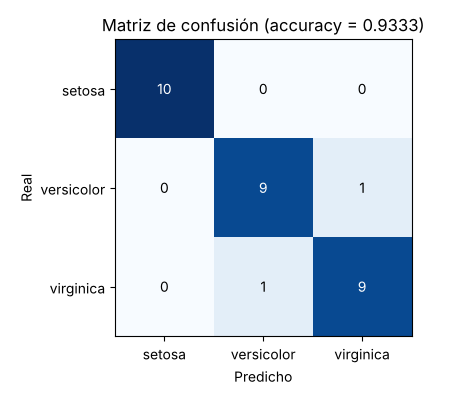

In [14]:
# Matriz de confusión a partir de reports/metrics.json
metricas = json.loads(config.METRICS_PATH.read_text())
cm = metricas["confusion_matrix"]
nombres = metricas["class_names"]

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), nombres)
ax.set_yticks(range(3), nombres)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i][j], ha="center", va="center",
                color="white" if cm[i][j] > 5 else "black")
ax.set_title(f"Matriz de confusión (accuracy = {metricas['test_accuracy']})")
plt.tight_layout()
plt.show()

**Lectura:** *setosa* se clasifica sin errores; la única confusión es entre *versicolor* y
*virginica*, que se solapan en tamaño (como muestra la gráfica de la sección 1). La exactitud en
validación cruzada (~0.96) y en prueba (~0.93) son consistentes, lo que sugiere que no hay sobreajuste.

## 6. Inferencia gobernada por el contrato

In [15]:
from src.predict import predict_record

casos = {
    "ejemplo válido del contrato": contrato["examples"]["valid_input"],
    "ejemplo inválido del contrato": contrato["examples"]["invalid_input"],
    "flor nueva (probable virginica)": {"sepal_length": 6.9, "sepal_width": 3.1,
                                        "petal_length": 5.6, "petal_width": 2.2},
}
for nombre, registro in casos.items():
    print(nombre, "->", json.dumps(predict_record(registro, contrato), ensure_ascii=False))

ejemplo válido del contrato -> {"status": "ok", "species": "setosa", "probabilities": {"setosa": 0.9808, "versicolor": 0.0192, "virginica": 0.0}}
ejemplo inválido del contrato -> {"status": "rejected", "errors": ["campo no permitido por el contrato: color", "sepal_length: tipo inválido (se esperaba float, llegó str)", "sepal_width: valor nulo no permitido", "petal_length: 12.0 fuera de rango [0.5, 7.5]", "petal_width: -0.3 fuera de rango [0.05, 3.0]"]}
flor nueva (probable virginica) -> {"status": "ok", "species": "virginica", "probabilities": {"setosa": 0.0, "versicolor": 0.0434, "virginica": 0.9566}}


## 7. Automatización: pipeline de 4 etapas con un solo comando (requisito 3.2)
`run_pipeline.py` ejecuta:
1. **Preparación de datos**: tipado y partición estratificada 80 % / 20 %.
2. **Validación y control de calidad**: contrato, nulos, tipos, rangos, proporción 80/20 y fugas.
3. **Entrenamiento y registro en MLflow**: métricas *accuracy* y *F1*, modelo guardado.
4. **Pruebas automatizadas** con pytest.

En la terminal, desde la raíz del repositorio (con el entorno virtual activo):

```bash
python run_pipeline.py                              # las 4 etapas
mlflow ui --backend-store-uri sqlite:///mlflow.db   # ver el experimento en http://127.0.0.1:5000
```

> Ejecuta la celda siguiente en tu equipo: su salida queda también en `reports/pipeline_run.log`
> como **evidencia de ejecución**.

In [ ]:
# Ejecuta las etapas 1 a 3 (la 4, pruebas, está en la sección 8)
resultado = subprocess.run([sys.executable, "run_pipeline.py", "--skip-tests"],
                           capture_output=True, text=True)
print(resultado.stdout)
print("Código de salida del pipeline:", resultado.returncode)

## 8. Pruebas automatizadas

In [17]:
# 28 pruebas: validación (tipos, nulos, rangos, estructura), contrato,
# umbral de calidad, partición estratificada, reproducibilidad e inferencia
resultado = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q"],
                           capture_output=True, text=True)
print(resultado.stdout[-600:])

............................                                             [100%]
28 passed in 1.15s



## 9. Conclusiones
- El pipeline es **reproducible**: semilla fija, dependencias declaradas en `requirements.txt`
  y una prueba que verifica que dos entrenamientos dan las mismas métricas.
- La **calidad de datos se controla antes de entrenar y antes de predecir**, con reglas tomadas de
  un contrato versionado y sin depender de librerías externas.
- El modelo alcanza ~0.93 de exactitud en prueba y ~0.96 en validación cruzada; los errores se
  concentran en *versicolor* vs. *virginica*.
- Cada ejecución queda registrada en **MLflow** (parámetros, accuracy, F1, modelo y contrato),
  lo que permite comparar corridas y recuperar exactamente el modelo entrenado.
- La integración continua (`.github/workflows/pipeline.yml`) ejecuta `make all` en cada *push*,
  dejando evidencia pública de que el pipeline corre desde cero en una máquina limpia.